# Exploración guiada (punto de partida, Hito 1)

**Responsable:** Leo (D)
**Revisor:** Dan (B)

Primera mirada a los reportes diarios de JHU CSSE entre el **22-ene y el 30-jun de 2020**, antes de
construir la plataforma completa (R1 a R3). Trabajamos sobre los CSV crudos de `data/raw/daily_reports/`,
que se descargan con `python -m src.pipeline descargar`.

## Qué debe quedar resuelto

- [x] Cargar `01-22-2020.csv`: primeras filas, número de filas y columnas, tipos de datos
- [x] Contar los nulos por columna y explicar qué significan aquí
- [x] Nombres a snake_case y fecha de actualización en AAAA-MM-DD
- [x] Unir los reportes de enero a junio de 2020 (cambios de esquema)
- [x] Top 10 de países al 30-jun-2020 y evolución de Chile (gráfico de líneas)
- [x] Perfilado automático (ydata-profiling) y tres observaciones

In [1]:
import sys, pathlib
RAIZ = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(RAIZ))
import re
import pandas as pd
import matplotlib.pyplot as plt
from src import config

# Si faltan los CSV crudos, se descargan (idempotente: no baja lo que ya existe)
if not (config.RAW_DIARIOS / '01-22-2020.csv').exists():
    from src.ingesta.descargar import descargar_todo
    descargar_todo()

config.FIGURAS.mkdir(parents=True, exist_ok=True)
pd.set_option('display.width', 160)

## 1. Cargar `01-22-2020.csv`: primeras filas, número de filas y columnas, tipos de datos

In [2]:
primer = pd.read_csv(config.RAW_DIARIOS / '01-22-2020.csv')
primer.head()

,Province/State,Country/Region,Last Update,Confirmed,Deaths,Recovered
0,Anhui,Mainland China,1/22/2020 17:00,1.0,NaN,NaN
1,Beijing,Mainland China,1/22/2020 17:00,14.0,NaN,NaN
2,Chongqing,Mainland China,1/22/2020 17:00,6.0,NaN,NaN
3,Fujian,Mainland China,1/22/2020 17:00,1.0,NaN,NaN
4,Gansu,Mainland China,1/22/2020 17:00,NaN,NaN,NaN


In [3]:
print(f'Filas: {primer.shape[0]}  ·  Columnas: {primer.shape[1]}')
primer.dtypes

Filas: 76  ·  Columnas: 6


Province/State        str
Country/Region        str
Last Update           str
Confirmed         float64
Deaths            float64
Recovered         float64
dtype: object

El primer reporte tiene solo **6 columnas** (esquema 1) y una fila por provincia o país. Los tipos que
infiere pandas ya muestran un problema: `Last Update` queda como texto (`object`) y no como fecha, y
`Deaths` y `Recovered` quedan como `float64` aunque son conteos, porque tienen valores vacíos (pandas
no admite nulos en `int64`).

## 2. Contar los nulos por columna y explicar qué significan aquí

In [4]:
nulos = pd.DataFrame({'nulos': primer.isna().sum(),
                      'pct': (100 * primer.isna().mean()).round(1)})
nulos

,nulos,pct
Province/State,12,15.8
Country/Region,0,0.0
Last Update,0,0.0
Confirmed,10,13.2
Deaths,37,48.7
Recovered,37,48.7


In [5]:
# ¿Quiénes no tienen provincia? Son los países que se informan como un todo.
primer.loc[primer['Province/State'].isna(), ['Country/Region', 'Confirmed']]

,Country/Region,Confirmed
35,Japan,2.0
36,Thailand,4.0
37,South Korea,1.0
39,Kiribati,0.0
40,Palau,0.0
42,Summer Olympics 2020,0.0
60,Tonga,0.0
61,Winter Olympics 2022,0.0
62,Antarctica,0.0
65,"Korea, North",0.0


**Qué significan los nulos en este conjunto:**

- `Province/State` vacío **no es un dato faltante**: indica que el país se informa completo, sin
  desagregar por provincia (Japón, Tailandia, Corea del Sur...). China y EE.UU., en cambio, se informan
  por provincia o estado.
- `Confirmed`, `Deaths` y `Recovered` vacíos significan, en la práctica, **que no se había informado
  ningún caso** de ese tipo en ese territorio (el día 1 casi nadie tenía fallecidos ni recuperados).
  Por eso más adelante un vacío en un acumulado se puede leer como 0 *solo* en los primeros días; en
  2021-2022 un vacío significa "no se informó" y no debe convertirse en 0 (sería imputar).
- `Last Update` no tiene nulos: siempre se sabe cuándo JHU tocó la fila.

Detalle llamativo de la tabla anterior: el archivo del 22-ene-2020 trae filas en 0 para
«Summer Olympics 2020», «Winter Olympics 2022», Antarctica, Kiribati o Corea del Norte. Son entidades
que JHU **agregó después a los archivos antiguos**; no se informaban en enero de 2020. Es la primera
señal de que hay filas que no son países (problema 6 de `docs/decisiones_calidad.md`).

## 3. Nombres a snake_case y fecha de actualización en AAAA-MM-DD

In [6]:
def a_snake(nombre: str) -> str:
    """'Province/State' -> 'province_state', 'Case-Fatality_Ratio' -> 'case_fatality_ratio'."""
    nombre = re.sub(r'[^0-9a-zA-Z]+', '_', nombre.strip())   # separadores -> _
    return nombre.strip('_').lower()

primer_std = primer.rename(columns=a_snake)
# Last Update viene en varios formatos según el día ('1/22/2020 17:00', '2020-03-01T10:13:19',
# '3/22/20 23:45'); format='mixed' los interpreta todos y luego se deja como AAAA-MM-DD.
primer_std['last_update'] = (pd.to_datetime(primer_std['last_update'], format='mixed')
                             .dt.strftime('%Y-%m-%d'))
print(list(primer_std.columns))
primer_std.head()

['province_state', 'country_region', 'last_update', 'confirmed', 'deaths', 'recovered']


,province_state,country_region,last_update,confirmed,deaths,recovered
0,Anhui,Mainland China,2020-01-22,1.0,NaN,NaN
1,Beijing,Mainland China,2020-01-22,14.0,NaN,NaN
2,Chongqing,Mainland China,2020-01-22,6.0,NaN,NaN
3,Fujian,Mainland China,2020-01-22,1.0,NaN,NaN
4,Gansu,Mainland China,2020-01-22,NaN,NaN,NaN


Ojo: `last_update` es **cuándo JHU modificó la fila, no la fecha del dato**. Para la fecha del dato se usa
el nombre del archivo (`MM-DD-AAAA.csv`), que es lo que hacemos al unir en el punto siguiente.

## 4. Unir los reportes de enero a junio de 2020 en un solo DataFrame

En este período aparecen **tres** formatos distintos además del inicial (ver enunciado, sección 2):

| Esquema | Desde | Cambio |
|---|---|---|
| 1 | 22-ene-2020 | 6 columnas, `Province/State`, `Country/Region`, `Last Update` |
| 2 | 1-mar-2020 | se agregan `Latitude` y `Longitude` |
| 3 | 22-mar-2020 | se renombran a `Province_State`, `Country_Region`, `Last_Update`, `Lat`, `Long_` y aparecen `FIPS`, `Admin2`, `Active`, `Combined_Key` |
| 4 | 29-may-2020 | se agregan `Incidence_Rate` y `Case-Fatality_Ratio` |

Si se concatenan sin unificar los nombres, `Country/Region` y `Country_Region` quedan como dos columnas
distintas y medio DataFrame queda vacío en cada una.

In [7]:
# Mismos nombres para la misma variable, sin importar el esquema
EQUIVALENCIAS = {'latitude': 'lat', 'longitude': 'long', 'long_': 'long',
                 'incidence_rate': 'incident_rate'}

def leer(ruta):
    df = pd.read_csv(ruta, dtype={'FIPS': str})
    df = df.rename(columns=lambda c: EQUIVALENCIAS.get(a_snake(c), a_snake(c)))
    df['fecha_reporte'] = pd.to_datetime(ruta.stem, format='%m-%d-%Y')   # fecha del DATO
    df['n_columnas_origen'] = df.shape[1] - 1
    return df

fechas = pd.date_range('2020-01-22', '2020-06-30', freq='D')
archivos = [config.RAW_DIARIOS / f'{f:%m-%d-%Y}.csv' for f in fechas]
ene_jun = pd.concat([leer(a) for a in archivos], ignore_index=True)
ene_jun['last_update'] = pd.to_datetime(ene_jun['last_update'], format='mixed').dt.strftime('%Y-%m-%d')

print(f'{len(archivos)} archivos -> {len(ene_jun):,} filas y {ene_jun.shape[1]} columnas')
print(list(ene_jun.columns))

161 archivos -> 350,945 filas y 16 columnas
['province_state', 'country_region', 'last_update', 'confirmed', 'deaths', 'recovered', 'fecha_reporte', 'n_columnas_origen', 'lat', 'long', 'fips', 'admin2', 'active', 'combined_key', 'incident_rate', 'case_fatality_ratio']


In [8]:
# Cuántas columnas traía cada archivo: los saltos son los cambios de esquema
cambios = (ene_jun.groupby('fecha_reporte')['n_columnas_origen'].first()
           .loc[lambda s: s.ne(s.shift())])
cambios.rename('columnas en el CSV').to_frame()

,columnas en el CSV
fecha_reporte,
2020-01-22,6
2020-03-01,8
2020-03-22,12
2020-05-29,14


In [9]:
# Filas por mes: el salto de marzo es el paso a condados de EE.UU. (esquema 3)
ene_jun.groupby(ene_jun['fecha_reporte'].dt.to_period('M')).size().rename('filas').to_frame()

,filas
fecha_reporte,
2020-01,864
2020-02,3378
2020-03,39198
2020-04,90311
2020-05,104228
2020-06,112966


El número de filas por día pasa de unas decenas a **más de 3.000 desde el 22-mar-2020**, porque EE.UU.
empieza a informar por condado (`admin2`). Esto importa: cualquier total por país hay que obtenerlo
**sumando** las filas del país, nunca tomando una fila.

## 5. Los 10 países con más casos acumulados al 30-jun-2020 y evolución de Chile

Antes de agrupar por país hay que normalizar los nombres: en enero China aparece como
«Mainland China» y Corea como «South Korea». Usamos el mismo mapa que la capa limpia
(`src/ingesta/unificar.py`).

In [10]:
from src.ingesta.unificar import NORMALIZAR_PAIS, PAIS_A_PROVINCIA

ene_jun['pais'] = ene_jun['country_region'].str.strip().replace(NORMALIZAR_PAIS)
ene_jun['pais'] = ene_jun['pais'].replace({k: v[0] for k, v in PAIS_A_PROVINCIA.items()})

# Acumulados por país y día = suma de sus provincias/condados
pais_dia = (ene_jun.groupby(['pais', 'fecha_reporte'])[['confirmed', 'deaths']]
            .sum(min_count=1).reset_index())

top10 = (pais_dia[pais_dia['fecha_reporte'] == '2020-06-30']
         .nlargest(10, 'confirmed')
         .assign(letalidad_aparente_pct=lambda d: (100 * d['deaths'] / d['confirmed']).round(1))
         .reset_index(drop=True))
top10.index += 1
top10[['pais', 'confirmed', 'deaths', 'letalidad_aparente_pct']]

,pais,confirmed,deaths,letalidad_aparente_pct
1,US,2653658.0,127095.0,4.8
2,Brazil,1412669.0,59792.0,4.2
3,Russia,646929.0,9306.0,1.4
4,India,585493.0,17400.0,3.0
5,United Kingdom,314157.0,56284.0,17.9
6,Peru,285213.0,37898.0,13.3
7,Chile,279393.0,5688.0,2.0
8,Spain,249271.0,28355.0,11.4
9,Italy,240578.0,34767.0,14.5
10,Iran,227662.0,10817.0,4.8


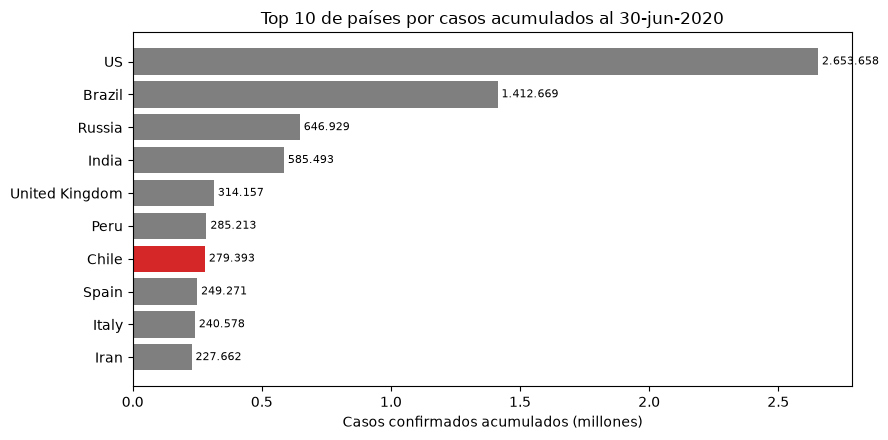

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.5))
t = top10.sort_values('confirmed')
colores = ['#d62728' if p == 'Chile' else '#7f7f7f' for p in t['pais']]
ax.barh(t['pais'], t['confirmed'] / 1e6, color=colores)
ax.set_xlabel('Casos confirmados acumulados (millones)')
ax.set_title('Top 10 de países por casos acumulados al 30-jun-2020')
for y, v in enumerate(t['confirmed']):
    ax.text(v / 1e6, y, f' {v:,.0f}'.replace(',', '.'), va='center', fontsize=8)
plt.tight_layout()
plt.savefig(config.FIGURAS / '00_top10_30jun2020.png', dpi=150)
plt.show()

In [12]:
chile = pais_dia[pais_dia['pais'] == 'Chile'].set_index('fecha_reporte').sort_index()
# Casos NUEVOS = diferencia del acumulado (los acumulados no se suman entre días)
chile['casos_nuevos'] = chile['confirmed'].diff()
chile['casos_nuevos_mm7'] = chile['casos_nuevos'].rolling(7).mean()

# Desde cuándo Chile se informa por regiones (cambio de granularidad)
filas_chile = ene_jun[ene_jun['pais'] == 'Chile'].groupby('fecha_reporte').size()
inicio_regional = filas_chile[filas_chile > 1].index.min()
print('Primer caso informado:', chile['confirmed'].first_valid_index().date())
print('Chile pasa a informarse por regiones el', inicio_regional.date())
print(chile.loc['2020-06-30', ['confirmed', 'deaths']])

Primer caso informado: 2020-03-03
Chile pasa a informarse por regiones el 2020-05-20
confirmed    279393.0
deaths         5688.0
Name: 2020-06-30 00:00:00, dtype: float64


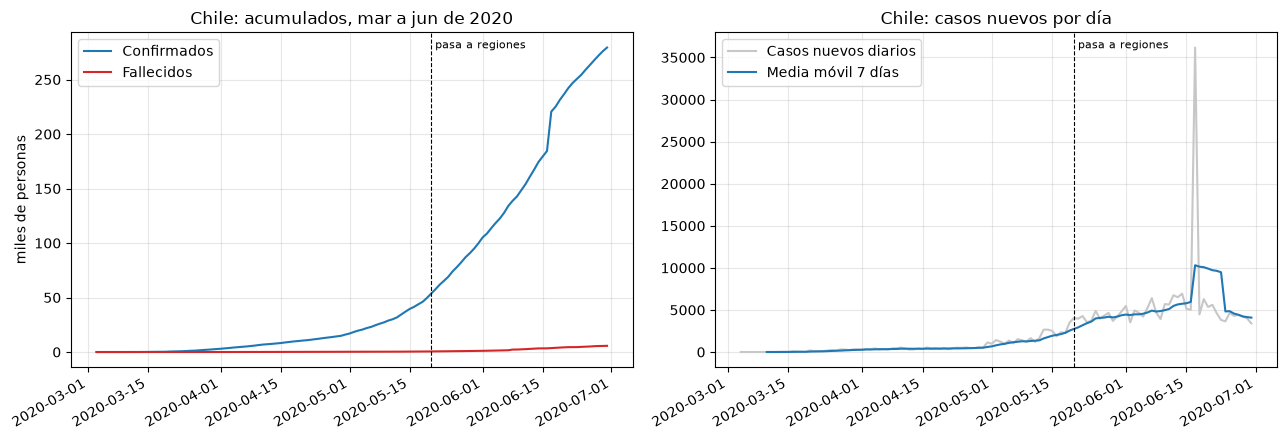

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
c = chile.loc['2020-03-01':]

ax1.plot(c.index, c['confirmed'] / 1e3, label='Confirmados', color='#1f77b4')
ax1.plot(c.index, c['deaths'] / 1e3, label='Fallecidos', color='#d62728')
ax1.set_title('Chile: acumulados, mar a jun de 2020')
ax1.set_ylabel('miles de personas')

ax2.plot(c.index, c['casos_nuevos'], color='#c7c7c7', label='Casos nuevos diarios')
ax2.plot(c.index, c['casos_nuevos_mm7'], color='#1f77b4', label='Media móvil 7 días')
ax2.set_title('Chile: casos nuevos por día')

for ax in (ax1, ax2):
    ax.axvline(inicio_regional, ls='--', color='k', lw=0.8)
    ax.text(inicio_regional, ax.get_ylim()[1] * 0.95, ' pasa a regiones', fontsize=8)
    ax.legend(); ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig(config.FIGURAS / '00_chile_ene_jun2020.png', dpi=150)
plt.show()

**Lectura:** Chile informa su primer caso el **3-mar-2020** y al 30-jun acumula **279.393 casos y
5.688 fallecidos**, el **7.º país del mundo** en casos a esa fecha pese a su población (unos 19 millones).
El crecimiento es lento hasta fines de abril y se acelera en mayo: la media móvil pasa de unos 500 a
cerca de 5.000 casos diarios en un mes. El **pico de 36.179 casos del 17-jun-2020 no es un día real de
contagios**: es la incorporación de golpe de casos informados con rezago (el día anterior y el siguiente
rondan los 5.000). Es un ejemplo de los «picos por acumulación de rezagos» de R2, y muestra por qué la
media móvil de 7 días es necesaria para leer la tendencia. Además, desde el **20-may-2020** Chile se
informa por regiones: para tener el total del país hay que sumar sus filas.

## 6. Perfilado automático y tres observaciones

Se usa **ydata-profiling** (requiere Python 3.11 o 3.12, ver README). El reporte HTML se guarda en
`reports/profiling/` (no se sube al repositorio por su tamaño). Si la librería no está instalada, la celda
hace un perfilado equivalente con pandas para no detener el notebook.

In [14]:
cols = ['fecha_reporte', 'pais', 'province_state', 'admin2', 'last_update', 'lat', 'long',
        'confirmed', 'deaths', 'recovered', 'active', 'incident_rate', 'case_fatality_ratio']
datos_perfil = ene_jun[cols]

try:
    from ydata_profiling import ProfileReport
    destino = config.REPORTS / 'profiling' / '00_ene_jun_2020.html'
    destino.parent.mkdir(parents=True, exist_ok=True)
    ProfileReport(datos_perfil, title='Reportes diarios JHU, ene-jun 2020', minimal=True).to_file(destino)
    print('Reporte de ydata-profiling en', destino)
except ImportError:
    print('ydata-profiling no está instalado: perfilado equivalente con pandas')

perfil = pd.DataFrame({
    'tipo': datos_perfil.dtypes.astype(str),
    'nulos_pct': (100 * datos_perfil.isna().mean()).round(1),
    'distintos': datos_perfil.nunique(),
    'min': datos_perfil.min(numeric_only=True),
    'max': datos_perfil.max(numeric_only=True),
})
perfil

ydata-profiling no está instalado: perfilado equivalente con pandas


,tipo,nulos_pct,distintos,min,max
active,float64,2.8,12467,0.0000,249015.00000
admin2,str,15.6,1875,NaN,NaN
case_fatality_ratio,float64,65.4,28383,0.0000,5400.00000
confirmed,float64,0.0,15173,0.0000,405843.00000
deaths,float64,0.1,3806,0.0000,48628.00000
fecha_reporte,datetime64[us],0.0,161,NaN,NaN
incident_rate,float64,65.5,65674,0.0000,13160.22687
last_update,str,0.0,163,NaN,NaN
lat,float64,3.0,4372,-71.9499,72.00000
long,float64,3.0,4589,-175.1982,178.06500


In [15]:
# Comprobaciones que respaldan las observaciones
desde_esquema = {c: ene_jun.loc[ene_jun[c].notna(), 'fecha_reporte'].min().date()
                 for c in ['lat', 'admin2', 'active', 'incident_rate']}
print('Primera fecha con dato:', desde_esquema)

pd_ = pais_dia.sort_values(['pais', 'fecha_reporte']).copy()
pd_['nuevos'] = pd_.groupby('pais')['confirmed'].diff()
retro = pd_[pd_['nuevos'] < 0]
print(f'Días país con acumulado que BAJA: {len(retro)} en {retro["pais"].nunique()} países')
print(retro.nsmallest(5, 'nuevos')[['pais', 'fecha_reporte', 'nuevos']].to_string(index=False))

print('Filas con fallecidos > confirmados:', int((ene_jun['deaths'] > ene_jun['confirmed']).sum()))
print('Filas de EE.UU.:', f"{(ene_jun['pais'] == 'US').mean():.0%} del total")

Primera fecha con dato: {'lat': datetime.date(2020, 3, 1), 'admin2': datetime.date(2020, 3, 22), 'active': datetime.date(2020, 3, 22), 'incident_rate': datetime.date(2020, 5, 29)}
Días país con acumulado que BAJA: 47 en 32 países
   pais fecha_reporte   nuevos
  Spain    2020-04-30 -23464.0
 France    2020-04-23  -1697.0
Ecuador    2020-05-07  -1583.0
Ecuador    2020-05-08  -1480.0
 France    2020-04-29  -1455.0
Filas con fallecidos > confirmados: 1357
Filas de EE.UU.: 85% del total


### Tres observaciones

1. **El conjunto está dominado por EE.UU.:** el 85 % de las 350.945 filas de enero a junio son condados de
   EE.UU., que aparecen recién con el esquema 3 (22-mar-2020). Un conteo de filas o un promedio simple por
   fila representa a EE.UU., no al mundo: todo análisis comparativo debe agregar primero por país.
2. **Las columnas nacen en fechas distintas:** `lat` y `long` existen desde el 1-mar, `admin2` y `active`
   desde el 22-mar e `incident_rate` y `case_fatality_ratio` desde el 29-may-2020 (por eso tienen 65 % de
   nulos en el período). Ese vacío no es un problema de calidad del dato sino del esquema, y es la razón de la
   columna «Existe desde» del diccionario de datos.
3. **Los acumulados no siempre se comportan como acumulados:** hay 47 días en 32 países en que el total
   baja (España pierde 23.464 casos el 30-abr-2020 por un cambio de criterio), 1.357 filas con más
   fallecidos que confirmados (900 de EE.UU., la mayoría filas «Unassigned» donde los fallecidos se
   asignan a un lugar distinto que los casos, y 397 del Reino Unido) y valores de `case_fatality_ratio` de hasta
   5.400 %, imposibles en un porcentaje. Por eso los casos nuevos se calculan con `diff` y se **marcan**
   los negativos (R2), en vez de corregirlos a mano.